# 02 — Preprocessing Pipeline Demo

Demonstrates the image preprocessing pipeline:
- Fundus auto-crop
- CLAHE enhancement
- Albumentations augmentation preview

> **Note:** Ben Graham colour normalisation and circular masking are available
> in `preprocess_image()` but disabled by default. The production pipeline
> uses only crop + CLAHE.

In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
from src.data_manager import ensure_dataset

ensure_dataset()
config.ensure_dirs()

print(f"Images dir: {config.EYEPACS_IMAGES_DIR} (exists: {os.path.isdir(config.EYEPACS_IMAGES_DIR)})")
print(f"Outputs dir: {config.OUTPUTS_DIR}")

/teamspace/studios/this_studio/diabetic_retinopathy/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Images dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped (exists: True)
Outputs dir: /teamspace/studios/this_studio/diabetic_retinopathy/outputs


In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.augmentations import get_train_transforms, get_valid_transforms
from src.preprocessing import (
    apply_circular_mask,
    apply_clahe,
    ben_graham_preprocessing,
    crop_fundus,
    preprocess_image,
)
from src.utils import seed_everything

seed_everything()

## 1. Step-by-Step Preprocessing

In [3]:
CLASS_CODE = dict(enumerate(config.CLASS_NAMES))
def find_image(images_dir, image_id):
    """Try common extensions and return the file path, or None."""
    for ext in ('.jpeg', '.jpg', '.png', '.JPEG', '.JPG'):
        p = os.path.join(images_dir, image_id + ext)
        if os.path.isfile(p):
            return p
    return None

# Pick a sample image
df = pd.read_csv(config.EYEPACS_LABELS_CSV)
cols_to_drop = [c for c in df.columns if c.startswith('Unnamed')]
df = df.drop(columns=cols_to_drop, errors='ignore')

# Choose one image from each class
sample_images = {}
for cls in range(config.NUM_CLASSES):
    row = df[df['level'] == cls].sample(1, random_state=config.SEED).iloc[0]
    img_path = find_image(config.EYEPACS_IMAGES_DIR, row['image'])
    if img_path is None:
        print(f'WARNING: Class {cls} — image not found for {row["image"]}')
        continue
    sample_images[cls] = img_path
    print(f'Class {cls} ({CLASS_CODE[cls]}): {img_path}')

Class 0 (No_DR): /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped/4095_right.jpeg
Class 1 (Mild): /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped/7797_left.jpeg
Class 2 (Moderate): /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped/3525_left.jpeg
Class 3 (Severe): /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped/39521_right.jpeg
Class 4 (Proliferative_DR): /teamspace/studios/this_studio/diabetic_retinopathy/dataset/resized_train_cropped/resized_train_cropped/8462_left.jpeg


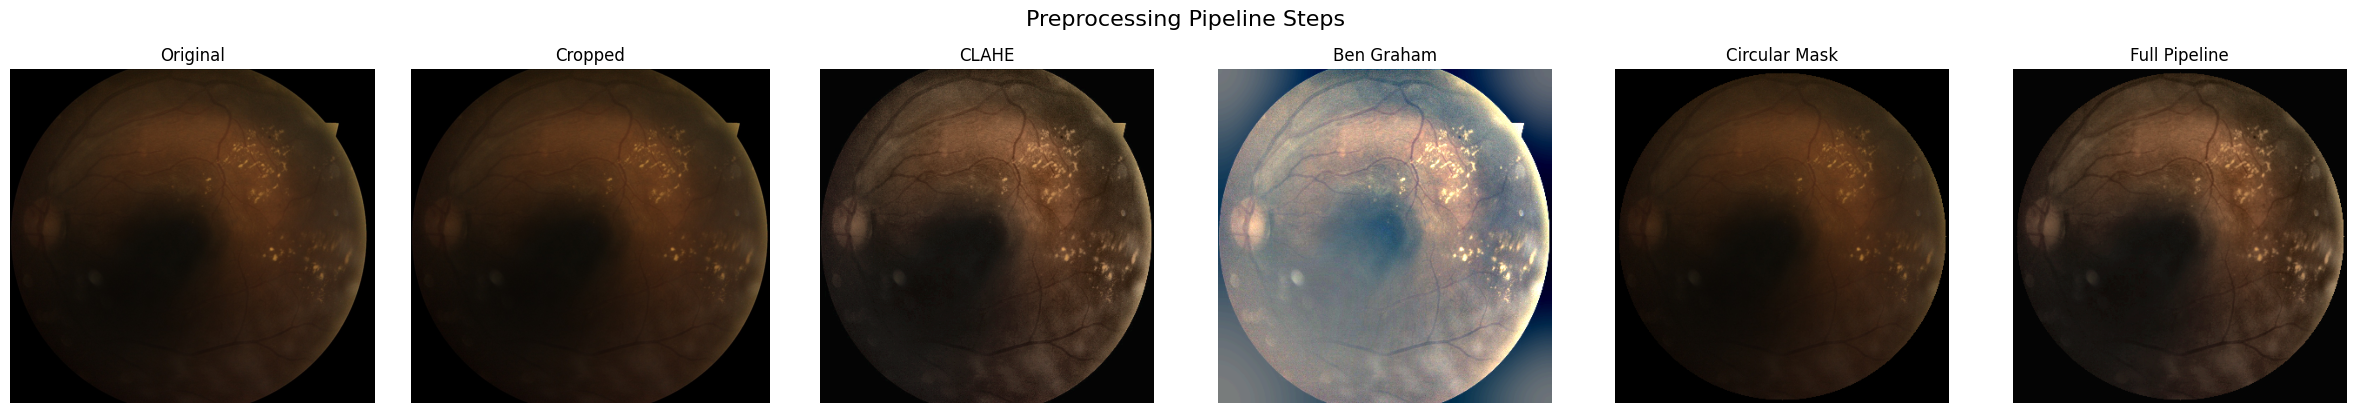

In [4]:
# Show step-by-step pipeline for one image
img_path = sample_images[2]  # Moderate DR
bgr = cv2.imread(img_path)
if bgr is None:
    raise FileNotFoundError(f"Could not read image at path: {img_path}")
original = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

steps = {
    'Original': original,
    'Cropped': crop_fundus(original.copy()),
    'CLAHE': apply_clahe(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Ben Graham': ben_graham_preprocessing(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Circular Mask': apply_circular_mask(cv2.resize(crop_fundus(original.copy()), (config.IMG_SIZE, config.IMG_SIZE))),
    'Full Pipeline': preprocess_image(original.copy()),
}

fig, axes = plt.subplots(1, len(steps), figsize=(4 * len(steps), 4))
fig.suptitle('Preprocessing Pipeline Steps', fontsize=16, y=1.02)

for ax, (name, img) in zip(axes, steps.items(), strict=True):
    ax.imshow(img)
    ax.set_title(name, fontsize=12)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'preprocessing_steps.png'), dpi=150, bbox_inches='tight')
plt.show()

## 2. Preprocessing Across All Classes

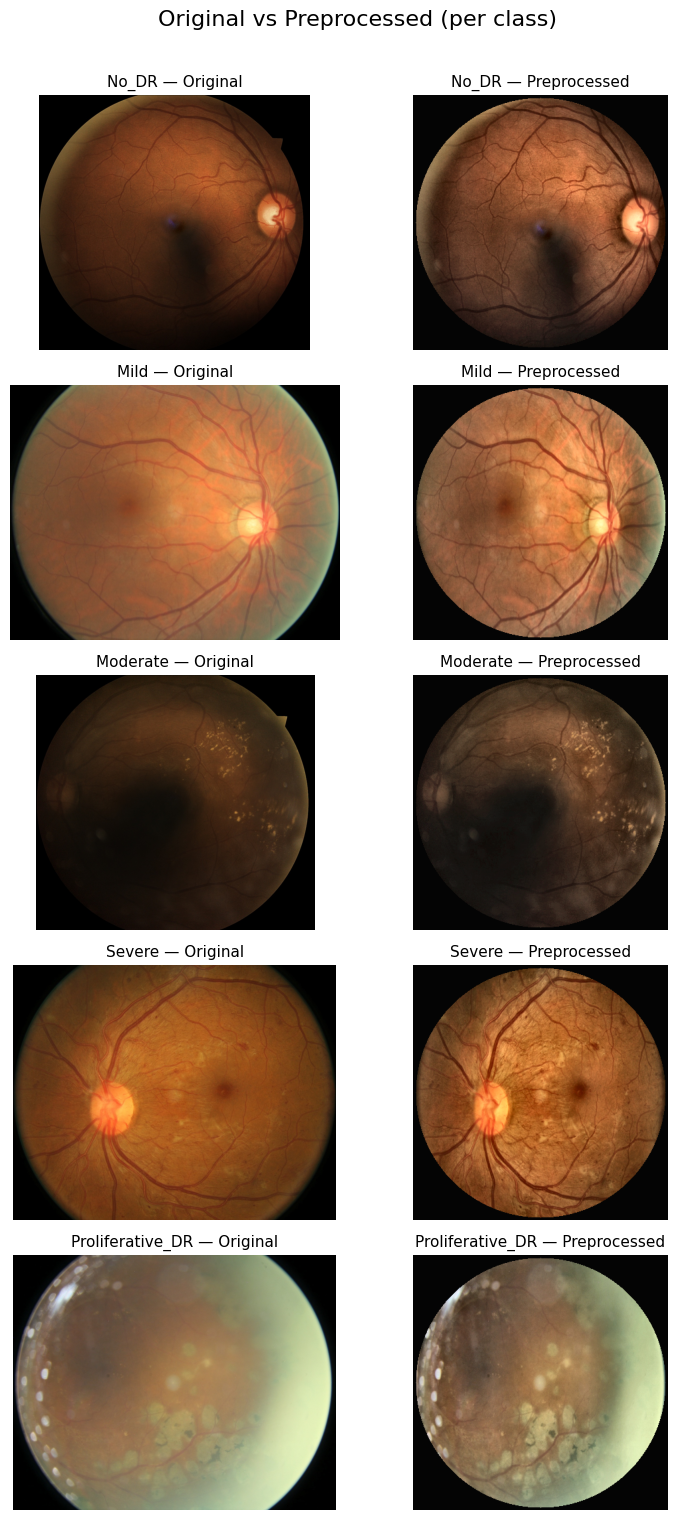

In [5]:
CLASS_CODE = dict(enumerate(config.CLASS_NAMES))
fig, axes = plt.subplots(config.NUM_CLASSES, 2, figsize=(8, 3 * config.NUM_CLASSES))
fig.suptitle('Original vs Preprocessed (per class)', fontsize=16, y=1.01)

for cls in range(config.NUM_CLASSES):
    bgr_img = cv2.imread(sample_images[cls])
    if bgr_img is None:
        raise FileNotFoundError(f"Could not read image for class {cls}: {sample_images[cls]}")

    img = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)
    processed = preprocess_image(img.copy())

    axes[cls, 0].imshow(img)
    axes[cls, 0].set_title(f'{CLASS_CODE[cls]} — Original', fontsize=11)
    axes[cls, 0].axis('off')

    axes[cls, 1].imshow(processed)
    axes[cls, 1].set_title(f'{CLASS_CODE[cls]} — Preprocessed', fontsize=11)
    axes[cls, 1].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'preprocessing_all_classes.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Augmentation Preview

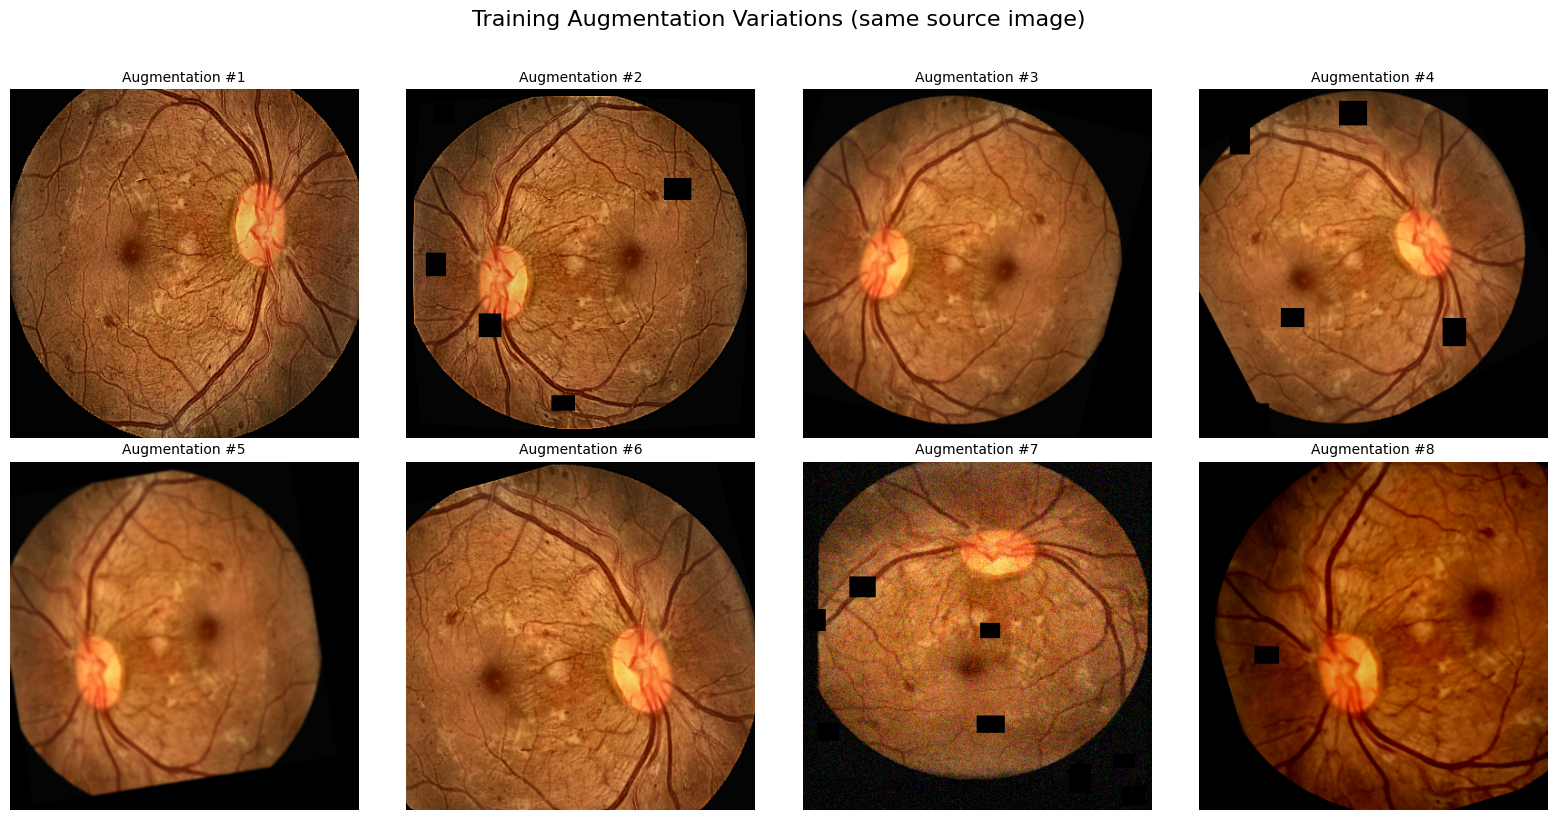

In [6]:
# Show multiple augmented versions of the same preprocessed image
img_path = sample_images[3]
bgr_aug = cv2.imread(img_path)
if bgr_aug is None:
    raise FileNotFoundError(f"Could not read image for augmentation preview: {img_path}")

rgb_aug = cv2.cvtColor(bgr_aug, cv2.COLOR_BGR2RGB)
processed = preprocess_image(rgb_aug)
train_tfm = get_train_transforms()

n_augments = 8
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Training Augmentation Variations (same source image)', fontsize=16, y=1.02)

for i, ax in enumerate(axes.flat):
    augmented = train_tfm(image=processed)['image']
    # Denormalise for display
    img_np = augmented.permute(1, 2, 0).numpy()
    img_np = img_np * np.array(config.IMG_STD) + np.array(config.IMG_MEAN)
    img_np = np.clip(img_np, 0, 1)
    ax.imshow(img_np)
    ax.set_title(f'Augmentation #{i+1}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig(os.path.join(config.FIGURES_DIR, 'augmentation_preview.png'), dpi=150, bbox_inches='tight')
plt.show()

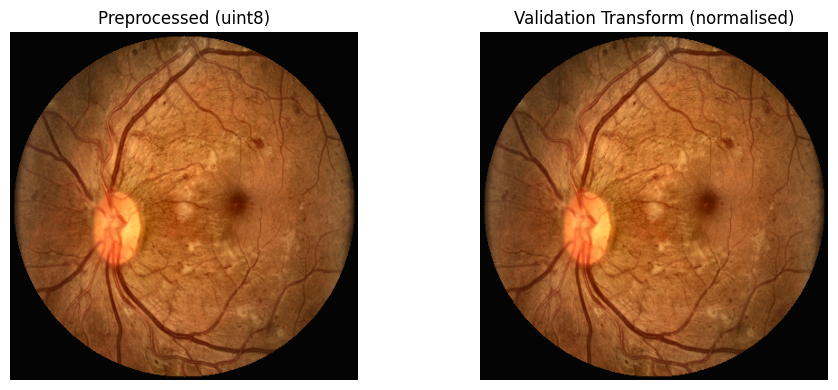

In [7]:
# Show validation transform (deterministic)
val_tfm = get_valid_transforms()
val_result = val_tfm(image=processed)['image']
img_np = val_result.permute(1, 2, 0).numpy()
img_np = img_np * np.array(config.IMG_STD) + np.array(config.IMG_MEAN)
img_np = np.clip(img_np, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(processed)
axes[0].set_title('Preprocessed (uint8)', fontsize=12)
axes[0].axis('off')

axes[1].imshow(img_np)
axes[1].set_title('Validation Transform (normalised)', fontsize=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()